# Kaggle Kick-start Workshop - Day 1
## Data Preparation: From Raw Data to Model-Ready

**Duration:** 2 hours 30 minutes

---

## What You'll Learn Today

By the end of today:
- ✅ Understand how Kaggle competitions work
- ✅ Explore data to find patterns
- ✅ Create new useful features
- ✅ Handle missing data properly
- ✅ Prepare data for modeling (Day 2)

---

## 📋 Session Plan

| Time | Topic | Duration |
|------|-------|----------|
| 2:00-2:15 PM | Kaggle Basics & Problem Setup | 15 min |
| 2:15-2:50 PM | Data Exploration (EDA) + Outliers | 35 min |
| 2:50-3:25 PM | Feature Engineering | 35 min |
| 3:25-3:35 PM | **BREAK**| 10 min |
| 3:35-3:55 PM | Handling Missing Data | 20 min |
| 3:55-4:20 PM | Final Preparation | 25 min |
| 4:20-4:30 PM | Recap & Q&A | 10 min |

---

## 1. Kaggle Basics

### The Titanic Challenge

**Goal:** Predict who survived the Titanic disaster

**Why this dataset?**
- Perfect for beginners
- Small enough to learn fast
- Real historical data
- Clear patterns to discover

### Files You Get

- `train.csv` - 891 passengers with survival info
- `test.csv` - 418 passengers without survival info
- `gender_submission.csv` - example of how to submit

---

## 2. Data Exploration - EDA

EDA = Exploratory Data Analysis = Understanding your data

### Setup Code (Run This First)



In [200]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')

# Load data
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')


In [201]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



### Step 1: Quick Look at Data




**What we have:**

| Column | What it means |
|--------|---------------|
| PassengerId | Just an ID number |
| Survived | **TARGET** - 0=died, 1=survived |
| Pclass | Ticket class (1=rich, 3=poor) |
| Name | Passenger name |
| Sex | male or female |
| Age | Age in years |
| SibSp | Number of siblings/spouses on board |
| Parch | Number of parents/children on board |
| Ticket | Ticket number |
| Fare | Ticket price |
| Cabin | Cabin number |
| Embarked | Port where got on (C/Q/S) |

### Step 2: Check for Missing Data



In [202]:
print(train.isnull().sum())


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64



**Output shows:**
- Age: 177 missing (19%)
- Cabin: 687 missing (77%)
- Embarked: 2 missing (0.2%)

**Key insight:** Cabin is mostly empty, Age has some gaps

### Step 3: Who Survived?



In [203]:

print(train['Survived'].value_counts())

print(train['Survived'].mean())


Survived
0    549
1    342
Name: count, dtype: int64
0.3838383838383838



**Result:** Only 38% survived → More people died

### Step 4: Does Gender Matter?



Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


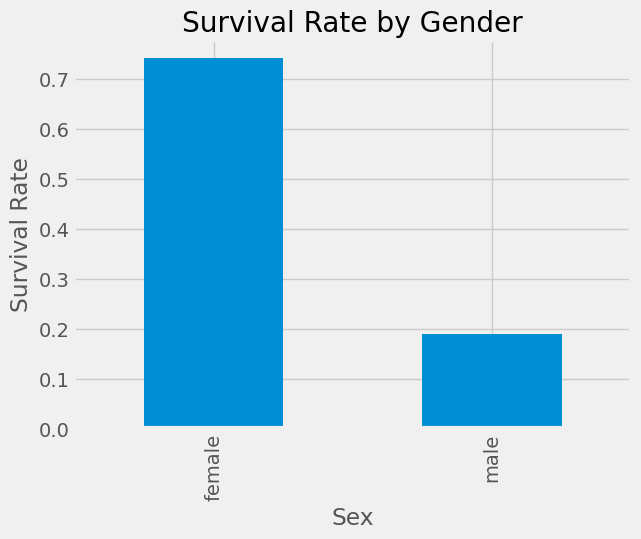

In [204]:
print(train.groupby('Sex')['Survived'].mean())

train.groupby('Sex')['Survived'].mean().plot(kind='bar')
plt.title('Survival Rate by Gender')
plt.ylabel('Survival Rate')
plt.show()


**Result:**
- Female: 74% survived ✅
- Male: 19% survived ❌

**Big insight:** "Women and children first" was real!

### Step 5: Does Class Matter?



Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


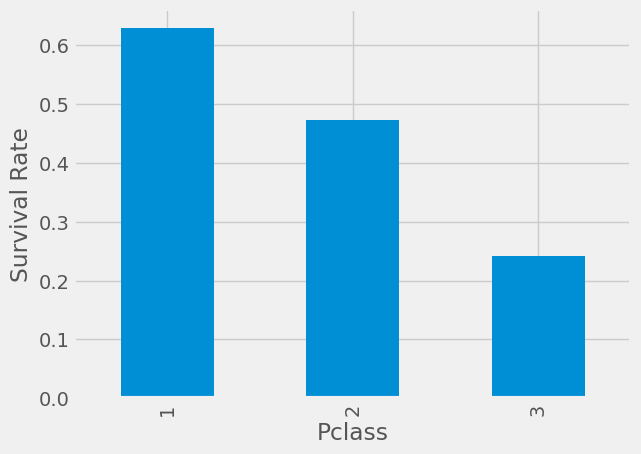

In [205]:
print(train.groupby('Pclass')['Survived'].mean())

train.groupby('Pclass')['Survived'].mean().plot(kind='bar')
plt.ylabel('Survival Rate')
plt.show()



**Result:**
- Class 1 (rich): 63% survived
- Class 2 (middle): 47% survived
- Class 3 (poor): 24% survived

**Insight:** Rich people had better access to lifeboats

### Step 6: Does Age Matter?



28.343689655172415
30.62617924528302


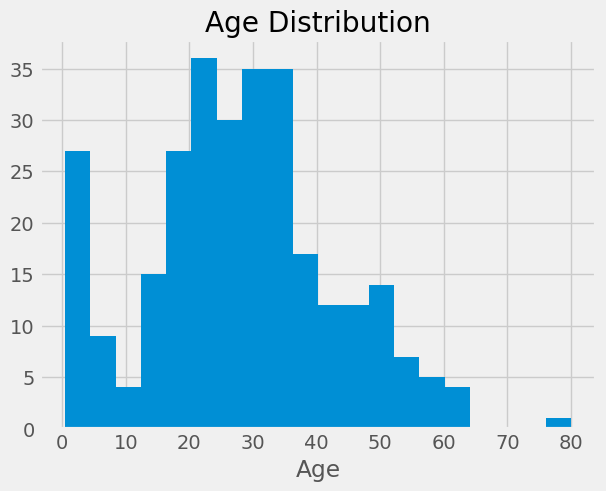

In [206]:

survived = train[train['Survived']==1]['Age']
died = train[train['Survived']==0]['Age']

print(survived.mean())
print(died.mean())

survived.hist(bins=20)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.show()


**Insight:** Slightly younger people survived more (kids first!)

### Step 7: Combine Multiple Features



In [207]:
train.groupby(['Sex', 'Pclass'])['Survived'].mean()


Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64


**This shows:**
- Female + Class 1 = 96% survival (best!)
- Male + Class 3 = 13% survival (worst!)

**Key Learning:** Multiple factors combine to affect survival

### Step 8: Detect and Handle Outliers

**What are outliers?** Extreme values that are very different from most data

**Why care?** Outliers can:
- Mess up our models
- Represent errors in data
- Or be real important values!

**Method:** Use IQR (Interquartile Range)

#### Check Age Outliers



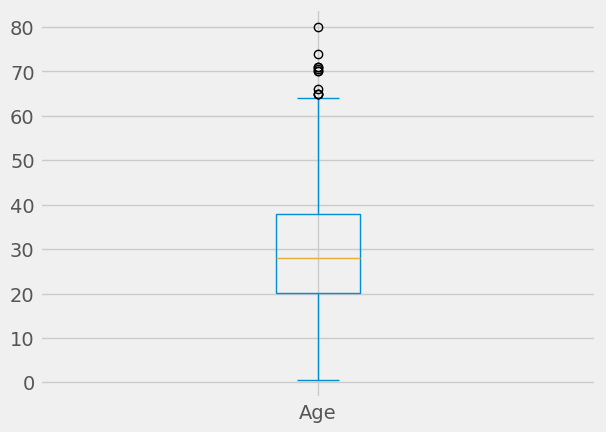

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64


In [208]:

train['Age'].plot(kind='box')
plt.show()

print(train['Age'].describe())



**For Age:** No major outliers (age 0-80 is reasonable)

#### Check Fare Outliers



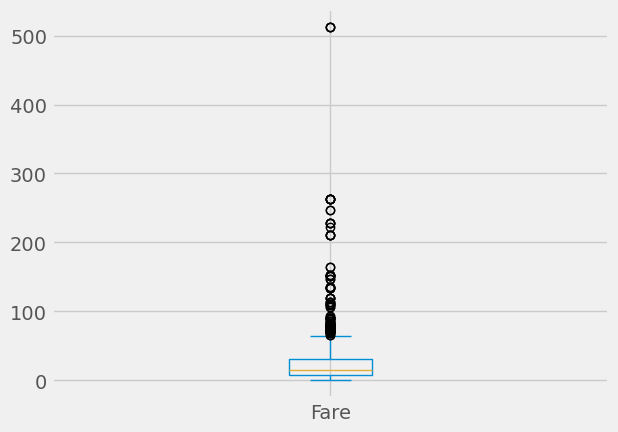

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [209]:
train['Fare'].plot(kind='box')

plt.show()

train['Fare'].describe()




**We see:** Some very high fares (over $500!) - these are outliers

#### Fix Fare Outliers Using IQR Method

**IQR Method Steps:**
1. Calculate Q1 (25th percentile) and Q3 (75th percentile)
2. Calculate IQR = Q3 - Q1
3. Find limits: Lower = Q1 - 1.5×IQR, Upper = Q3 + 1.5×IQR
4. Cap values outside these limits



<Axes: >

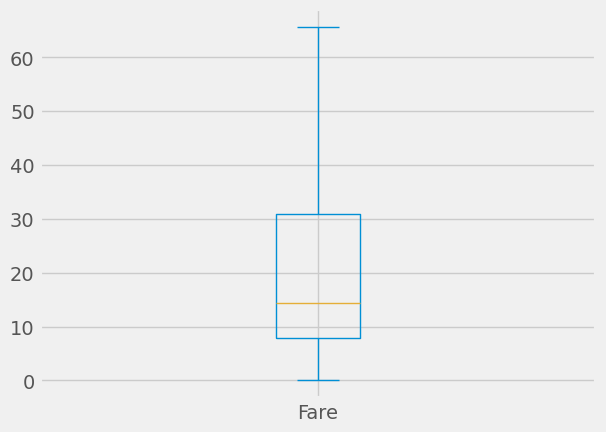

In [210]:
def whisker(col):
    q1 = np.percentile(col, 25)
    q3 = np.percentile(col, 75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return lower, upper

ll, ul = whisker(train['Fare'])
train['Fare'] = np.where(train['Fare'] < ll, ll, train['Fare'])
train['Fare'] = np.where(train['Fare'] > ul, ul, train['Fare'])

ll1, ul1= whisker(test['Fare'])
test['Fare'] = np.where(test['Fare'] < ll1, ll1, test['Fare'])
test['Fare'] = np.where(test['Fare'] > ul1, ul1, test['Fare'])

train['Fare'].plot(kind='box')


**Alternative Approach (Simpler):** 
If you don't want to remove outliers, the FareGroup binning we'll do later automatically handles them!




**Decision for Titanic:**
- Age outliers: Keep them (80-year-olds are real!)
- Fare outliers: Cap them (but binning will help anyway)

---

## 3. Feature Engineering

Feature Engineering = Creating new useful columns from existing data

### Why Do This?

Raw data alone might not be enough. We can create better features that help models learn patterns.

### Feature 1: Extract Title from Name

**Idea:** Names contain titles (Mr, Mrs, Miss) that tell us:
- Gender (already have this)
- Age group (Master = boy, Miss = young)
- Social status (rare titles = important people)



In [211]:
print(train['Name'].iloc[0])

train['Title'] = train['Name'].str.split(', ').str[1].str.split('.').str[0]
test['Title'] = test['Name'].str.split(', ').str[1].str.split('.').str[0]

print(train['Title'].value_counts())

Braund, Mr. Owen Harris
Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64



**We get:** Mr, Miss, Mrs, Master, and rare ones like Dr, Rev, etc.

**Clean up rare titles:**



In [212]:
# Group rare titles together
rare_titles = ['Dr', 'Rev', 'Col', 'Major', 'Capt', 'Sir', 'Lady', 
               'Don', 'Jonkheer', 'the Countess', 'Dona']

train['Title'] = train['Title'].replace(rare_titles, 'Rare')
test['Title'] = test['Title'].replace(rare_titles, 'Rare')

# Also fix variations of Miss/Mrs
train['Title'] = train['Title'].replace('Mlle', 'Miss')
train['Title'] = train['Title'].replace('Ms', 'Miss')
train['Title'] = train['Title'].replace('Mme', 'Mrs')

test['Title'] = test['Title'].replace('Mlle', 'Miss')
test['Title'] = test['Title'].replace('Ms', 'Miss')
test['Title'] = test['Title'].replace('Mme', 'Mrs')

# Check survival by title
print(train.groupby('Title')['Survived'].mean())


Title
Master    0.575000
Miss      0.702703
Mr        0.156673
Mrs       0.793651
Rare      0.347826
Name: Survived, dtype: float64



**Result:**
- Mrs: 79% survived (married women)
- Miss: 70% survived (young women)
- Master: 57% survived (boys)
- Mr: 16% survived (men)
- Rare: 35% survived

**Insight:** Title is very predictive!

### Feature 2: Family Size

**Idea:** People traveling with family might help each other



FamilySize
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: Survived, dtype: float64


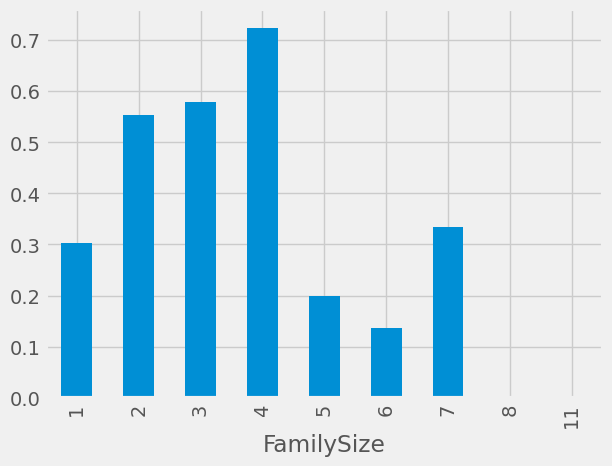

In [213]:
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1
test['FamilySize'] = test['SibSp'] + test['Parch'] + 1

print(train.groupby('FamilySize')['Survived'].mean())

train.groupby('FamilySize')['Survived'].mean().plot(kind='bar')
plt.show()



**Result:**
- Size 1 (alone): 30% survived
- Size 2-4: 50-70% survived (best!)
- Size 5+: 20% survived (large families struggled)

**Insight:** Medium families did best, very large families struggled

### Feature 3: Is Alone?

**Simpler version of family size:**



In [214]:
train['IsAlone'] = np.where(train['FamilySize'] == 1, 1, 0)
test['IsAlone'] = np.where(test['FamilySize'] == 1, 1, 0)

print(train.groupby('IsAlone')['Survived'].mean())


IsAlone
0    0.505650
1    0.303538
Name: Survived, dtype: float64



**Result:**
- Not alone: 50% survived
- Alone: 30% survived

### Feature 4: Age Groups

**Problem:** Age is continuous (0-80), hard for models to learn  
**Solution:** Group ages into categories



In [215]:
def create_age_group(age):
    if pd.isnull(age):
        return 'Unknown'
    elif age < 5:
        return 'Baby'
    elif age < 12:
        return 'Child'
    elif age < 18:
        return 'Teen'
    elif age < 25:
        return 'Student'
    elif age < 35:
        return 'YoungAdult'
    elif age < 60:
        return 'Adult'
    else:
        return 'Senior'

# Apply to both datasets
train['AgeGroup'] = train['Age'].apply(create_age_group)
test['AgeGroup'] = test['Age'].apply(create_age_group)

# Check survival
print(train.groupby('AgeGroup')['Survived'].mean())


AgeGroup
Adult         0.416268
Baby          0.675000
Child         0.428571
Senior        0.269231
Student       0.345455
Teen          0.488889
Unknown       0.293785
YoungAdult    0.388060
Name: Survived, dtype: float64



**Result:** Babies and children survived more

### Feature 5: Fare Groups

**Same idea as age - group continuous fare into bands:**



In [216]:
train['Fare'].min()

0.0

In [217]:
# Define fixed bins based on domain knowledge
fare_bins = [0, 10, 20, 50, 600]
fare_labels = ['Low', 'Medium', 'High', 'VeryHigh']

train['FareGroup'] = pd.cut(train['Fare'], bins=fare_bins, labels=fare_labels, include_lowest=True)
test['FareGroup'] = pd.cut(test['Fare'], bins=fare_bins, labels=fare_labels, include_lowest=True)

In [218]:
train['FareGroup'].isnull().sum()

np.int64(0)


**Result:** Higher fare → higher survival (same as Pclass)

### Feature 6: Cabin Information

**Problem:** 77% missing - can't use cabin number  
**Solution:** Just record if they HAD a cabin or not



In [219]:
train['HasCabin'] = np.where(train['Cabin'].notna(), 1, 0)
test['HasCabin'] = np.where(test['Cabin'].notna(), 1, 0)

print(train.groupby('HasCabin')['Survived'].mean())


HasCabin
0    0.299854
1    0.666667
Name: Survived, dtype: float64



**Result:**
- Has cabin: 67% survived
- No cabin: 30% survived

**Insight:** Having a cabin recorded = wealthier = better survival

### Summary of New Features

We created:
1. **Title** - from Name (social status)
2. **FamilySize** - from SibSp + Parch (family connections)
3. **IsAlone** - from FamilySize (traveling alone)
4. **AgeGroup** - from Age (life stage)
5. **FareGroup** - from Fare (wealth level)
6. **HasCabin** - from Cabin (wealth indicator)

---

## 4. Handling Missing Data

### What's Missing?



In [220]:
print("Training set missing values:")
print(train.isnull().sum())

print("\nTest set missing values:")
print(test.isnull().sum())


Training set missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
Title            0
FamilySize       0
IsAlone          0
AgeGroup         0
FareGroup        0
HasCabin         0
dtype: int64

Test set missing values:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
Title            0
FamilySize       0
IsAlone          0
AgeGroup         0
FareGroup        1
HasCabin         0
dtype: int64



### Strategy 1: Embarked (2 missing in train)

**Approach:** Use the most common value



In [221]:
most_common = train['Embarked'].mode()[0]
print(most_common)

train['Embarked'].fillna(most_common, inplace=True)
test['Embarked'].fillna(most_common, inplace=True)

train['Embarked'].value_counts()


S


/var/folders/y1/m2zrq70s2zxdl8_hc2lm4tyr0000gn/T/ipykernel_4740/50384074.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train['Embarked'].fillna(most_common, inplace=True)
/var/folders/y1/m2zrq70s2zxdl8_hc2lm4tyr0000gn/T/ipykernel_4740/50384074.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always 

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


### Strategy 2: Age (many missing)

**Approach:** Use Title to guess age

Why? Because:
- Master = young boys (average ~5 years)
- Miss = young women (average ~22 years)
- Mr = adult men (average ~32 years)
- Mrs = married women (average ~36 years)



In [222]:
title_ages = train.groupby('Title')['Age'].median()
print(title_ages)

def fill_age(row):
    if pd.isnull(row['Age']):
        return title_ages[row['Title']]
    return row['Age']

train['Age'] = train.apply(fill_age, axis=1)
test['Age'] = test.apply(fill_age, axis=1)

train['AgeGroup'] = train['Age'].apply(create_age_group)
test['AgeGroup'] = test['Age'].apply(create_age_group)

Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64



### Strategy 3: Fare (1 missing in test)

**Approach:** Use average fare for that passenger's class



In [223]:
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
Title            0
FamilySize       0
IsAlone          0
AgeGroup         0
FareGroup        1
HasCabin         0
dtype: int64

In [224]:
# Find the missing fare passenger's class
missing_fare_idx = test[test['Fare'].isnull()].index
if len(missing_fare_idx) > 0:
    pclass = test.loc[missing_fare_idx[0], 'Pclass']
    median_fare = train[train['Pclass'] == pclass]['Fare'].median()
    test.loc[missing_fare_idx[0], 'Fare'] = median_fare
    print(f"Filled missing fare with ${median_fare:.2f}")

# Recreate fare groups for test
test['FareGroup'] = pd.cut(test['Fare'], bins=fare_bins, 
                            labels=['Low','Medium','High','VeryHigh'], include_lowest=True)

Filled missing fare with $8.05



### Verify - No More Missing!



In [225]:
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
Title            0
FamilySize       0
IsAlone          0
AgeGroup         0
FareGroup        0
HasCabin         0
dtype: int64


Should show 0 missing values!

---

## 5. Final Preparation (25 min)

### Step 1: Convert Categories to Numbers

**Why?** Models need numbers, not text



In [226]:
# Sex: male=0, female=1
train['Sex'] = train['Sex'].map({'male': 0, 'female': 1})
test['Sex'] = test['Sex'].map({'male': 0, 'female': 1})

# Embarked: S=1, C=2, Q=3
train['Embarked'] = train['Embarked'].map({'S': 1, 'C': 2, 'Q': 3})
test['Embarked'] = test['Embarked'].map({'S': 1, 'C': 2, 'Q': 3})

# Title: Mr=1, Miss=2, Mrs=3, Master=4, Rare=5
title_map = {'Mr': 1, 'Miss': 2, 'Mrs': 3, 'Master': 4, 'Rare': 5}
train['Title'] = train['Title'].map(title_map)
test['Title'] = test['Title'].map(title_map)

# AgeGroup: Baby=1, Child=2, ..., Senior=7
age_map = {'Baby': 1, 'Child': 2, 'Teen': 3, 'Student': 4, 
           'YoungAdult': 5, 'Adult': 6, 'Senior': 7}
train['AgeGroup'] = train['AgeGroup'].map(age_map)
test['AgeGroup'] = test['AgeGroup'].map(age_map)

# FareGroup: Low=1, Medium=2, High=3, VeryHigh=4
fare_map = {'Low': 1, 'Medium': 2, 'High': 3, 'VeryHigh': 4}
train['FareGroup'] = train['FareGroup'].map(fare_map)
test['FareGroup'] = test['FareGroup'].map(fare_map)

train['FareGroup'].value_counts()


FareGroup
1    336
3    216
2    179
4    160
Name: count, dtype: int64


### Step 2: Select Final Features

**Keep useful features, drop unnecessary ones:**



In [227]:
# Features we want to keep
keep_features = [
    'Pclass',       # Original
    'Sex',          # Original (encoded)
    'Embarked',     # Original (encoded)
    'Title',        # Created from Name
    'AgeGroup',     # Created from Age
    'FareGroup',    # Created from Fare
    'FamilySize',   # Created from SibSp+Parch
    'IsAlone',      # Created from FamilySize
    'HasCabin'      # Created from Cabin
]

# For training: keep features + target
train_final = train[keep_features + ['Survived']]

# For test: keep only features
test_final = test[keep_features]

print("Selected features:", keep_features)
print("Train shape:", train_final.shape)
print("Test shape:", test_final.shape)


Selected features: ['Pclass', 'Sex', 'Embarked', 'Title', 'AgeGroup', 'FareGroup', 'FamilySize', 'IsAlone', 'HasCabin']
Train shape: (891, 10)
Test shape: (418, 9)


In [228]:
train_final.head()

,Pclass,Sex,Embarked,Title,AgeGroup,FareGroup,FamilySize,IsAlone,HasCabin,Survived
0,3,0,1,1,4,1,2,0,0,0
1,1,1,2,3,6,4,2,0,1,1
2,3,1,1,2,5,1,1,1,0,1
3,1,1,1,3,6,4,2,0,1,1
4,3,0,1,1,6,1,1,1,0,0


In [229]:
train_final.isnull().sum() 

Pclass        0
Sex           0
Embarked      0
Title         0
AgeGroup      0
FareGroup     0
FamilySize    0
IsAlone       0
HasCabin      0
Survived      0
dtype: int64


---

## 6. Recap & Key Takeaways


### What We Did Today

✅ **Understood the Problem**
- Kaggle workflow
- Titanic dataset structure
- Evaluation approach

✅ **Explored the Data (EDA)**
- Found missing values
- Discovered survival patterns:
  - Females survived more (74% vs 19%)
  - Rich passengers survived more (Class 1: 63%)
  - Children survived more
  - Medium families did best
- Detected and handled outliers in Fare using IQR method

✅ **Created New Features**
- Title (from Name)
- FamilySize (from SibSp + Parch)
- IsAlone (from FamilySize)
- AgeGroup (from Age)
- FareGroup (from Fare)
- HasCabin (from Cabin)

✅ **Handled Missing Data**
- Embarked: filled with mode ('S')
- Age: filled based on Title
- Fare: filled based on Pclass

✅ **Prepared Final Dataset**
- Encoded categories as numbers
- Selected useful features
- Created train/validation split
- Saved everything for Day 2

### The Big Picture

```
RAW DATA → EDA → OUTLIERS → FEATURE ENGINEERING → IMPUTATION → ENCODING → MODEL-READY
(messy)  (understand) (fix extreme) (create new)    (fill gaps)   (numbers)   (clean)
```



---

## Homework

Try these before Day 2:

1. **Experiment with a new feature**
   - Try: Deck from Cabin (first letter)
   - Does it improve patterns?

2. **Try different age groups**
   - What if you use only 3 groups: Child, Adult, Senior?
   - Does simpler work better?

3. **Visualize one more pattern**
   - Create a plot showing Fare vs Survival
   - What do you notice?

---

*See you on Day 2!*

---